# RL-ASL 4-PLD Clinical Inference

Loads the trained 4-PLD SAC actor, runs the full whole-brain rollout on real
clinical NIfTI data, saves `CBF_RL.nii.gz` / `ATT_RL.nii.gz`, and displays
slices.

**Before it will produce maps**, you must manually confirm that the input
file order matches the training PLD/LD table. `clinical_preprocess()` in
`rl_4pld_validation.py` intentionally never marks this "verified" on its
own — filenames alone can't prove acquisition order, and getting it wrong
silently mislabels every CBF/ATT value. This is a deliberate safety gate,
not a bug, and the cell below will stop the notebook until you clear it.

In [1]:
%matplotlib inline
from pathlib import Path
import numpy as np
import nibabel as nib
import torch
import matplotlib.pyplot as plt

from rl_4pld_validation import clinical_preprocess, load_agent, rollout
from rl_asl_4pld import PLD_SEC, LD_SEC, CBF_MIN, CBF_MAX, ATT_MIN, ATT_MAX

BASE = Path.cwd()
DATA_ROOT = BASE / 'test data'
OUTPUT_ROOT = BASE / 'rl_inference_output'
CHECKPOINT = BASE / 'experiments' / 'rl_sac_4pld_trained' / 'notebook_results' / 'sac_asl_final.pth'
OUTPUT_ROOT.mkdir(exist_ok=True)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
agent, checkpoint_report = load_agent(CHECKPOINT, device)
clinical_report, clinical_data = clinical_preprocess(DATA_ROOT)

print('Using device:', device)
print('Checkpoint validation:', 'PASS' if checkpoint_report['keys_match'] else 'FAIL')
print('Actor mode: evaluation')
print('Actions: deterministic')
print('Optimizer called: False')
print('Training PLD table (s):', PLD_SEC.tolist())
print('Training LD table (s): ', LD_SEC.tolist())
print('CBF bounds:', float(CBF_MIN), '-', float(CBF_MAX))
print('ATT bounds:', float(ATT_MIN), '-', float(ATT_MAX))
print('Clinical acquisition status:', clinical_report['status'])
print('Valid voxels:', clinical_report.get('valid_voxels'))
if clinical_report['status'] == 'MISSING_INPUTS':
    print('STOP:', clinical_report)

Torch: 2.5.1+cu121 | CUDA available: True


d:\reinforcement learning\asl-github-repo\rl_4pld_validation.py:124: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  raw = torch.load(checkpoint, map_location=device)


Using device: cuda
Checkpoint validation: PASS
Actor mode: evaluation
Actions: deterministic
Optimizer called: False
Training PLD table (s): [1.524999976158142, 2.0250000953674316, 2.5250000953674316, 3.0250000953674316]
Training LD table (s):  [1.7999999523162842, 1.7999999523162842, 1.7999999523162842, 1.7999999523162842]
CBF bounds: 0.0 - 100.0
ATT bounds: 0.5 - 3.0
Clinical acquisition status: AMBIGUOUS_ACQUISITION_ORDER
Valid voxels: 211458


In [2]:
print('Sorted perfusion files (index -> filename):')
for i, f in enumerate(clinical_report['perf_files']):
    print(f'  [{i}] {f}')
print()
print('Sorted M0 files (order does not affect the result -- M0 is averaged')
print('across all 4 volumes inside clinical_preprocess):')
for i, f in enumerate(clinical_report['m0_files']):
    print(f'  [{i}] {f}')
print()
print('These perfusion files must correspond, IN THIS ORDER, to:')
print('  PLD (s):', PLD_SEC.tolist())
print('  LD  (s):', LD_SEC.tolist())
print()
print(clinical_report.get('message', ''))

Sorted perfusion files (index -> filename):
  [0] perf_1525.nii
  [1] perf_2025.nii
  [2] perf_2525.nii
  [3] perf_3025.nii

Sorted M0 files (order does not affect the result -- M0 is averaged
across all 4 volumes inside clinical_preprocess):
  [0] M0_1525.nii
  [1] M0_2025.nii
  [2] M0_2525.nii
  [3] M0_3025.nii

These perfusion files must correspond, IN THIS ORDER, to:
  PLD (s): [1.524999976158142, 2.0250000953674316, 2.5250000953674316, 3.0250000953674316]
  LD  (s): [1.7999999523162842, 1.7999999523162842, 1.7999999523162842, 1.7999999523162842]

Filenames do not encode the training PLD/LD table [0.700,2.033,3.366,0.700]/[1.333,1.333,1.333,4.000]; clinical maps were not inferred.


## Manual acquisition-order confirmation (required)

1. Check your scanner protocol / DICOM headers / acquisition sheet for the
   actual PLD/LD of each of the 4 files listed above.
2. Compare that to the sorted order printed above and the training table
   (`PLD_SEC` / `LD_SEC`).
3. In the next cell, set `ACQUISITION_ORDER_VERIFIED = True` **only if
   you've confirmed the sorted order is correct**. If it's *not* correct,
   set `PERF_ORDER` to the index permutation that fixes it — e.g.
   `PERF_ORDER = [2, 0, 3, 1]` means "the file currently at index 2 is
   actually PLD position 0", etc.

Nothing downstream runs until this cell passes.

In [3]:
# ============================================================
# MANUAL VERIFICATION -- edit these two lines yourself, then run
# ============================================================
ACQUISITION_ORDER_VERIFIED = True   # set True only after checking against your real protocol
PERF_ORDER = None                    # e.g. [2, 0, 3, 1] to reorder perf_files, or None to keep sorted order

if clinical_report['status'] == 'MISSING_INPUTS':
    raise RuntimeError(f"Cannot proceed, inputs missing: {clinical_report}")

if not ACQUISITION_ORDER_VERIFIED:
    raise RuntimeError(
        'STOP: set ACQUISITION_ORDER_VERIFIED = True in this cell only after '
        'confirming the perf_files order (printed above) against your actual '
        'acquisition protocol. No CBF/ATT maps are generated until then.'
    )

observed = clinical_data['observed']
if PERF_ORDER is not None:
    assert sorted(PERF_ORDER) == [0, 1, 2, 3], 'PERF_ORDER must be a permutation of [0,1,2,3]'
    observed = observed[..., PERF_ORDER]
    print('Applied PERF_ORDER override:', PERF_ORDER)
else:
    print('Using sorted file order as-is (confirmed correct).')

valid_mask = clinical_data['valid_mask']
mask_img = clinical_data['mask_img']
shape3d = clinical_data['shape']
print('Proceeding with', int(valid_mask.sum()), 'voxels.')

Using sorted file order as-is (confirmed correct).
Proceeding with 211458 voxels.


In [4]:
CHUNK_SIZE = 100_000  # lower this if you hit a GPU memory error

coords = np.argwhere(valid_mask)
n_voxels = len(coords)
print(f'Running SAC rollout on {n_voxels} voxels '
      f'(chunks of {CHUNK_SIZE}, max_steps=12, init_mode="random", deterministic actions)...')

cbf_all = np.empty(n_voxels, dtype=np.float32)
att_all = np.empty(n_voxels, dtype=np.float32)

for start in range(0, n_voxels, CHUNK_SIZE):
    end = min(start + CHUNK_SIZE, n_voxels)
    idx = coords[start:end]
    chunk_signal = torch.tensor(
        observed[idx[:, 0], idx[:, 1], idx[:, 2], :],
        dtype=torch.float32,
        device=device,
    )
    env, _, _, _ = rollout(agent, chunk_signal, init_mode='random', max_steps=12)
    cbf_all[start:end] = env.cbf_est.detach().cpu().numpy()
    att_all[start:end] = env.att_est.detach().cpu().numpy()
    print(f'  voxels {start}-{end} done')

print('Rollout complete.')

Running SAC rollout on 211458 voxels (chunks of 100000, max_steps=12, init_mode="random", deterministic actions)...
  voxels 0-100000 done
  voxels 100000-200000 done
  voxels 200000-211458 done
Rollout complete.


In [5]:
CBF_map = np.full(shape3d, np.nan, dtype=np.float32)
ATT_map = np.full(shape3d, np.nan, dtype=np.float32)
CBF_map[coords[:, 0], coords[:, 1], coords[:, 2]] = cbf_all
ATT_map[coords[:, 0], coords[:, 1], coords[:, 2]] = att_all

affine = mask_img.affine
CBF_save = np.nan_to_num(CBF_map, nan=0.0)
ATT_save = np.nan_to_num(ATT_map, nan=0.0)

cbf_path = OUTPUT_ROOT / 'CBF_RL.nii.gz'
att_path = OUTPUT_ROOT / 'ATT_RL.nii.gz'
nib.save(nib.Nifti1Image(CBF_save, affine), cbf_path)
nib.save(nib.Nifti1Image(ATT_save, affine), att_path)
print('Saved:', cbf_path)
print('Saved:', att_path)

Saved: d:\reinforcement learning\asl-github-repo\rl_inference_output\CBF_RL.nii.gz
Saved: d:\reinforcement learning\asl-github-repo\rl_inference_output\ATT_RL.nii.gz


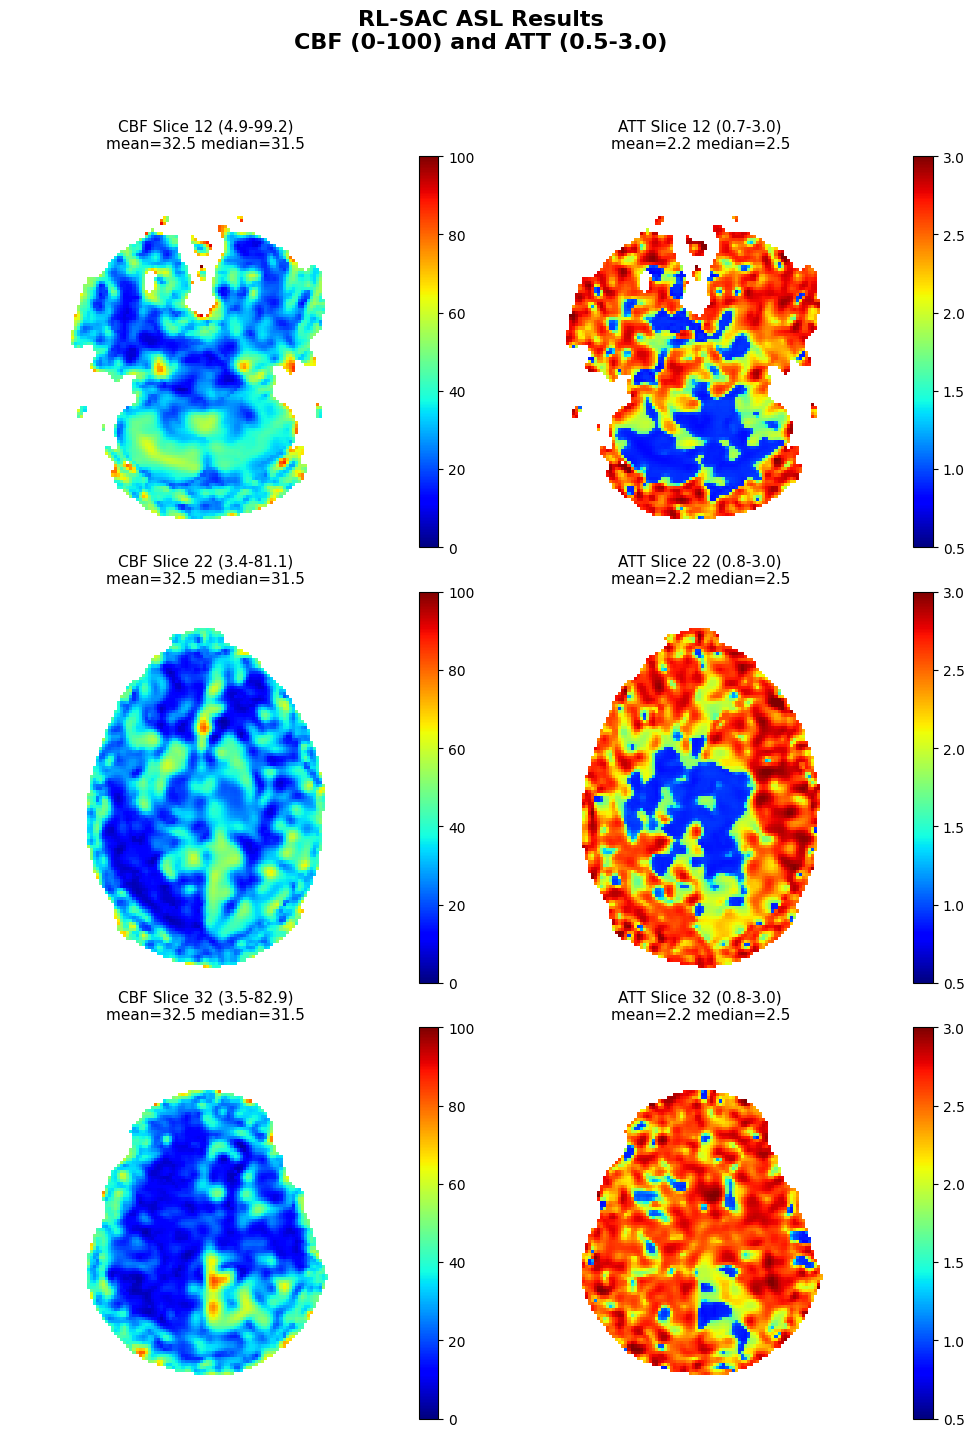

In [6]:
global_cbf_mean = np.nanmean(CBF_map[valid_mask])
global_cbf_median = np.nanmedian(CBF_map[valid_mask])
global_att_mean = np.nanmean(ATT_map[valid_mask])
global_att_median = np.nanmedian(ATT_map[valid_mask])

sz = shape3d
mid = sz[2] // 2
slices = sorted(set(s for s in (mid - 10, mid, mid + 10) if 0 <= s < sz[2]))
if not slices:
    slices = [mid]

fig, axes = plt.subplots(len(slices), 2, figsize=(10, 5 * len(slices)))
axes = np.atleast_2d(axes)
fig.patch.set_facecolor('white')
fig.suptitle(
    f'RL-SAC ASL Results\nCBF ({float(CBF_MIN):.0f}-{float(CBF_MAX):.0f}) '
    f'and ATT ({float(ATT_MIN):.1f}-{float(ATT_MAX):.1f})',
    fontsize=16, fontweight='bold', y=0.98
)

for i, z in enumerate(slices):
    cbf_slice = np.rot90(CBF_map[:, :, z])
    cbf_masked = np.ma.masked_where(np.isnan(cbf_slice) | (cbf_slice == 0), cbf_slice)
    cbf_min = cbf_masked.min() if cbf_masked.count() > 0 else 0.0
    cbf_max = cbf_masked.max() if cbf_masked.count() > 0 else 0.0
    im_cbf = axes[i, 0].imshow(cbf_masked, cmap='jet', vmin=float(CBF_MIN), vmax=float(CBF_MAX))
    axes[i, 0].set_title(
        f'CBF Slice {z} ({cbf_min:.1f}-{cbf_max:.1f})\nmean={global_cbf_mean:.1f} median={global_cbf_median:.1f}',
        color='black', fontsize=11
    )
    axes[i, 0].axis('off')
    cb = fig.colorbar(im_cbf, ax=axes[i, 0], fraction=0.046, pad=0.04)
    cb.ax.yaxis.set_tick_params(color='black', labelcolor='black')
    cb.outline.set_edgecolor('black')

    att_slice = np.rot90(ATT_map[:, :, z])
    att_masked = np.ma.masked_where(np.isnan(att_slice) | (att_slice == 0), att_slice)
    att_min = att_masked.min() if att_masked.count() > 0 else 0.0
    att_max = att_masked.max() if att_masked.count() > 0 else 0.0
    im_att = axes[i, 1].imshow(att_masked, cmap='jet', vmin=float(ATT_MIN), vmax=float(ATT_MAX))
    axes[i, 1].set_title(
        f'ATT Slice {z} ({att_min:.1f}-{att_max:.1f})\nmean={global_att_mean:.1f} median={global_att_median:.1f}',
        color='black', fontsize=11
    )
    axes[i, 1].axis('off')
    cb2 = fig.colorbar(im_att, ax=axes[i, 1], fraction=0.046, pad=0.04)
    cb2.ax.yaxis.set_tick_params(color='black', labelcolor='black')
    cb2.outline.set_edgecolor('black')

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
fig_path = OUTPUT_ROOT / 'rl_slices.png'
plt.savefig(fig_path, facecolor='white', bbox_inches='tight', dpi=150)
plt.show()
